# SCIKIT-LEARN MASTERY — NOTEBOOK 4
## Chapters 16–20: K-Nearest Neighbors → Support Vector Machines → Naive Bayes → Decision Trees (API Focus) → Ensemble Learning Overview

Continuing directly from Notebook 3.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–15 *(Notebooks 1–3)*
- [x] KNN
- [x] SVM
- [x] Naive Bayes
- [x] Decision Trees (API mastery — theory assumed known)
- [x] Ensemble Learning (overview map)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification, make_moons
np.random.seed(42)


---
# CHAPTER 16 — K-NEAREST NEIGHBORS

## 1. Concept
`KNeighborsClassifier`/`Regressor` make no explicit assumption about the data's functional form — a prediction for a new point is simply the (weighted) majority vote / average of its `k` closest training points. There is no real "training" phase beyond storing the data (`.fit()` is nearly instantaneous); all the computational cost happens at **prediction time**, searching for neighbors.

## 2. Key Parameters
| Parameter | Meaning |
|---|---|
| `n_neighbors` (k) | How many neighbors to consult — small k = flexible/noisy (high variance); large k = smooth/simple (high bias) |
| `weights` | `'uniform'` (all k neighbors count equally) or `'distance'` (closer neighbors count more) |
| `metric` | Distance function — `'minkowski'` (default, generalizes Euclidean/Manhattan via `p`), `'manhattan'`, `'cosine'`, etc. |
| `p` | Power parameter for Minkowski distance: `p=2` is Euclidean (default), `p=1` is Manhattan |
| `algorithm` | Internal neighbor-search structure — `'auto'`, `'ball_tree'`, `'kd_tree'`, `'brute'` — affects speed, not results |
| `n_jobs` | Parallelize the neighbor search across CPU cores |


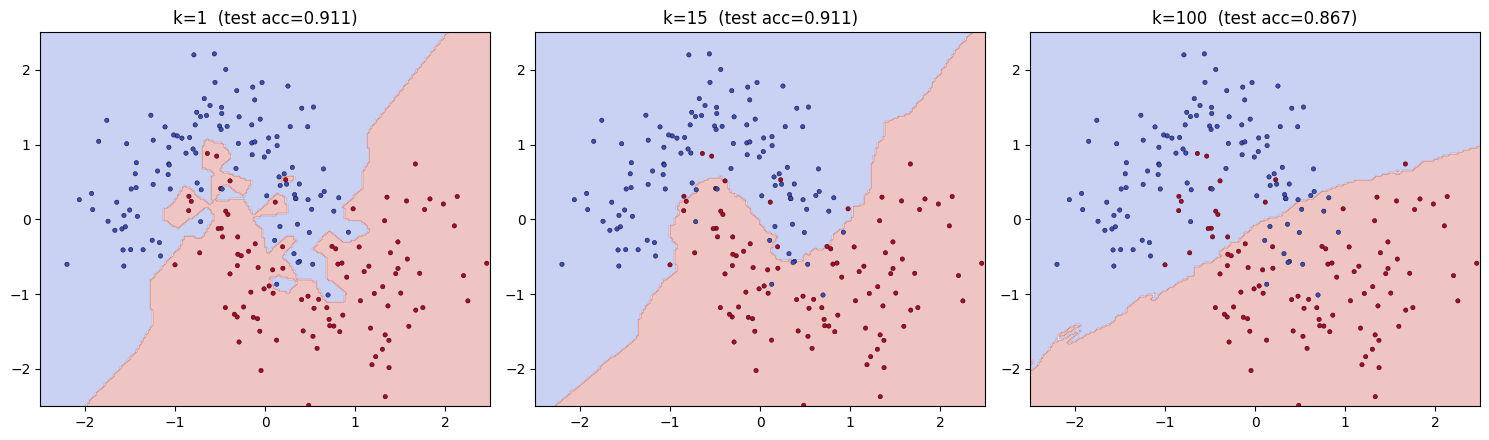

In [2]:
from sklearn.neighbors import KNeighborsClassifier

X_knn, y_knn = make_moons(n_samples=300, noise=0.25, random_state=42)
X_knn_train, X_knn_test, y_knn_train, y_knn_test = train_test_split(X_knn, y_knn, test_size=0.3, random_state=42)

# ALWAYS scale before KNN -- it is a pure distance-based method
scaler_knn = StandardScaler().fit(X_knn_train)
X_knn_train_s = scaler_knn.transform(X_knn_train)
X_knn_test_s = scaler_knn.transform(X_knn_test)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, [1, 15, 100]):
    model = KNeighborsClassifier(n_neighbors=k).fit(X_knn_train_s, y_knn_train)
    test_acc = model.score(X_knn_test_s, y_knn_test)

    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_knn_train_s[:, 0], X_knn_train_s[:, 1], c=y_knn_train, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(f"k={k}  (test acc={test_acc:.3f})")

plt.tight_layout()
plt.show()


### Interpretation of the Decision Boundary Plot
- **k=1**: an extremely jagged, overfit boundary — every single training point (including noise) gets its own tiny region; high variance, likely to generalize poorly.
- **k=15**: a much smoother, more reasonable boundary — this is typically closer to the sweet spot for this dataset.
- **k=100**: an almost-straight boundary — with `k` approaching a third of the training set, the model is essentially averaging over huge neighborhoods, washing out genuine local structure; high bias, underfitting.

This is a direct, visual demonstration of the bias-variance tradeoff purely through one hyperparameter — exactly the kind of curve a validation curve (Chapter 51) would formalize numerically.

### Common Mistakes
- Forgetting to scale features before KNN — since it's a **pure distance-based method with no other correction mechanism**, this mistake has an even more direct and severe impact here than for Logistic Regression/SVM (which at least have regularization terms partially interacting with scale).
- Choosing an even `k` for binary classification — can produce tie votes (broken arbitrarily); odd `k` values avoid this.
- Assuming KNN "trains fast" makes it cheap overall — prediction time scales with training set size (naive brute-force is `O(n)` per prediction), making KNN potentially **slow and memory-heavy at inference time** on large datasets, the opposite tradeoff profile from most other models.

### Best Practices
- Always scale features before KNN.
- Tune `n_neighbors` via cross-validation/validation curve (Chapter 51) rather than guessing.
- Be mindful of prediction-time cost for large training sets — KNN's the "expensive to predict" outlier compared to other model families.

### Interview Insight
**Q: Why is KNN often described as having "no training phase," and what's the practical consequence of that?**
A: `.fit()` for KNN essentially just stores the training data (optionally building a spatial index like a KD-tree) — there's no optimization/learning of parameters happening, unlike gradient-based or split-based models. The practical consequence is an inverted cost profile: training is nearly free, but **every prediction** requires searching for nearest neighbors among the stored training data, making KNN potentially slow and memory-intensive at inference time, especially on large datasets — the opposite tradeoff from a model like Logistic Regression, which is expensive to train but essentially free to predict with afterward.

### Mini Exercise
Sweep `n_neighbors` from 1 to 50 in steps of 2 (to keep k odd), plot test accuracy against `k`, and identify the approximate k that maximizes it — a manual preview of Chapter 51's `validation_curve`.

### Quiz (Chapter 16)
1. Why does small `k` correspond to high variance and large `k` to high bias?
2. Why is scaling especially critical for KNN specifically, more so than for some other scale-sensitive models?
3. What is KNN's unusual cost profile (training vs. prediction time) compared to most other models?


---
# CHAPTER 17 — SUPPORT VECTOR MACHINES

## 1. Concept
`SVC` finds the decision boundary that **maximizes the margin** — the distance between the boundary and the nearest points of each class (the "support vectors"). With a non-linear `kernel`, SVM implicitly projects data into a higher-dimensional space where a linear separator *would* work, without ever explicitly computing that projection (the "kernel trick").

## 2. Key Parameters
| Parameter | Meaning |
|---|---|
| `C` | Regularization — **same inverse convention as Logistic Regression** (small `C` = wider margin, more tolerance for misclassified points, simpler boundary; large `C` = narrower margin, fits training data more tightly) |
| `kernel` | `'linear'`, `'poly'`, `'rbf'` (default — good general-purpose non-linear choice), `'sigmoid'` |
| `gamma` | (RBF/poly kernels) how far a single training point's influence reaches — small `gamma` = far reach (smoother boundary); large `gamma` = short reach (more complex, can overfit) |
| `degree` | Polynomial kernel's degree |
| `probability` | If `True`, enables `predict_proba()` via an internal costly cross-validation-based calibration — off by default since it slows down fitting meaningfully |


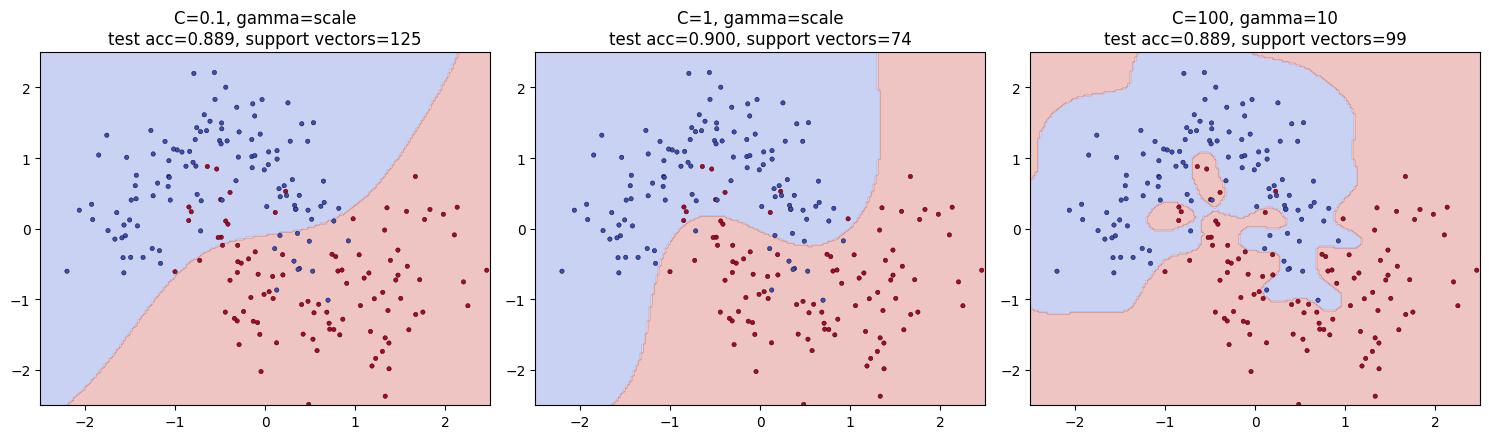

In [3]:
from sklearn.svm import SVC

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (C, gamma) in zip(axes, [(0.1, "scale"), (1, "scale"), (100, 10)]):
    model = SVC(C=C, gamma=gamma, kernel="rbf").fit(X_knn_train_s, y_knn_train)
    test_acc = model.score(X_knn_test_s, y_knn_test)
    n_sv = model.n_support_.sum()

    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_knn_train_s[:, 0], X_knn_train_s[:, 1], c=y_knn_train, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(f"C={C}, gamma={gamma}\ntest acc={test_acc:.3f}, support vectors={n_sv}")

plt.tight_layout()
plt.show()


### Interpretation
- **C=0.1** (weak regularization... wait, weak *penalty for margin violations* — small C tolerates more misclassified points): a wide, smooth margin, many support vectors — a simpler, potentially underfit boundary.
- **C=1, gamma='scale'** (a reasonable default): a balanced boundary.
- **C=100, gamma=10** (large C, large gamma): a tight, wiggly boundary hugging individual points closely — classic overfitting signature, and note it also tends to use fewer support vectors concentrated right at the noisy boundary.

### `LinearSVC`/`LinearSVR` — The Faster Linear-Only Alternative


In [4]:
from sklearn.svm import LinearSVC
import time

# LinearSVC uses a different, much faster optimization algorithm specifically for the linear-kernel case
# -- prefer it over SVC(kernel='linear') whenever you specifically know you want a linear boundary
start = time.time()
SVC(kernel="linear").fit(X_knn_train_s, y_knn_train)
svc_time = time.time() - start

start = time.time()
LinearSVC(max_iter=5000).fit(X_knn_train_s, y_knn_train)
linsvc_time = time.time() - start

print(f"SVC(kernel='linear') fit time:  {svc_time*1000:.2f} ms")
print(f"LinearSVC fit time:              {linsvc_time*1000:.2f} ms")
print("\nOn larger datasets this gap widens dramatically -- SVC's general kernel machinery")
print("doesn't specialize for the linear case, while LinearSVC does.")


SVC(kernel='linear') fit time:  8.70 ms
LinearSVC fit time:              4.25 ms

On larger datasets this gap widens dramatically -- SVC's general kernel machinery
doesn't specialize for the linear case, while LinearSVC does.


### Internal Working / Computational Limitations
`SVC`'s training complexity scales roughly **quadratically to cubically** with the number of samples — it becomes genuinely impractical (extremely slow) beyond roughly tens of thousands of samples in standard form. This is precisely why `LinearSVC` (a different, more scalable optimization approach specific to the linear case) and `SGDClassifier` (a stochastic-gradient linear approximation) exist as alternatives when you need something SVM-like at larger scale.

### Common Mistakes
- Using `SVC(kernel='linear')` on a large dataset instead of `LinearSVC` — needlessly slow, since `SVC`'s general kernel machinery isn't optimized for the linear case the way `LinearSVC`'s dedicated algorithm is.
- Forgetting to scale features — SVM's margin-maximization is inherently distance-based, exactly like KNN, and equally scale-sensitive.
- Setting `probability=True` without knowing it triggers a genuinely slower internal calibration procedure — fine for small datasets, a real cost concern at scale (revisited directly in Chapter 31 on calibration).
- Assuming `SVC` scales gracefully to huge datasets the way linear models or tree ensembles often do — it generally does not, without switching to `LinearSVC`/`SGDClassifier` or subsampling.

### Best Practices
- Always scale features before SVM.
- Use `LinearSVC` (not `SVC(kernel='linear')`) whenever a linear boundary is specifically what you want.
- For datasets beyond roughly tens of thousands of rows, seriously consider whether `SVC` with a non-linear kernel is computationally feasible at all, versus a tree ensemble or `SGDClassifier`.

### Interview Insight
**Q: Why might SVM become impractical on a dataset with 500,000 rows, and what would you use instead?**
A: `SVC`'s training time scales roughly quadratically-to-cubically with sample count, making it computationally prohibitive well before 500,000 rows in standard form. For a genuinely linear decision boundary at that scale, `LinearSVC` (a specialized, more scalable linear-SVM optimizer) or `SGDClassifier` (stochastic gradient descent, naturally scalable) are the standard substitutes; for a non-linear boundary at that scale, tree-based ensembles (Random Forest, Gradient Boosting) are typically the more practical choice, since they scale far more gracefully with sample count.

### Mini Exercise
Fit `SVC(kernel='rbf', gamma='scale')` with `C` swept across `[0.01, 0.1, 1, 10, 100]`, plotting `model.n_support_.sum()` (total support vector count) against `C` — observe whether support vector count trends up or down as `C` increases, and reason about why.

### Quiz (Chapter 17)
1. What does the "kernel trick" let SVM do without explicitly computing a high-dimensional projection?
2. Why does SVC's `C` follow the same inverse-regularization convention as Logistic Regression's `C`?
3. When should you use `LinearSVC` instead of `SVC(kernel='linear')`?
4. Why does `probability=True` add real computational cost?


---
# CHAPTER 18 — NAIVE BAYES

## 1. Concept
Naive Bayes applies Bayes' theorem with a deliberately "naive" (and almost always technically false) assumption: **every feature is conditionally independent given the class**. Despite this strong simplification, it's often a surprisingly strong, extremely fast baseline — especially for **text classification**, where its independence assumption is a less severe distortion than it sounds (individual word presence often *is* reasonably close to independent, conditional on a document's topic).

## 2. The Variants — Choose Based on Feature Type
| Class | Assumes features are... | Typical use case |
|---|---|---|
| `GaussianNB` | Continuous, normally distributed | General numerical tabular data |
| `MultinomialNB` | Discrete counts (e.g., word counts) | **Text classification** (with `CountVectorizer`/`TfidfVectorizer`, Chapter 63) |
| `BernoulliNB` | Binary (0/1) | Text with binary word-presence features, or genuinely binary feature sets |
| `ComplementNB` | Discrete counts | Text classification specifically on **imbalanced** classes — often outperforms `MultinomialNB` there |


In [5]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score
import time

wine = load_wine(as_frame=True)
Xw, yw = wine.data, wine.target
Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.3, random_state=42, stratify=yw)

start = time.time()
gnb = GaussianNB().fit(Xw_train, yw_train)
gnb_time = time.time() - start
gnb_acc = accuracy_score(yw_test, gnb.predict(Xw_test))

print(f"GaussianNB -- fit time: {gnb_time*1000:.3f} ms, test accuracy: {gnb_acc:.4f}")
print("\nNote: no scaling was needed -- Naive Bayes estimates per-feature class-conditional")
print("distributions independently, so feature SCALE doesn't distort inter-feature comparisons")
print("the way it does for distance-based methods like KNN/SVM.")


GaussianNB -- fit time: 4.051 ms, test accuracy: 1.0000

Note: no scaling was needed -- Naive Bayes estimates per-feature class-conditional
distributions independently, so feature SCALE doesn't distort inter-feature comparisons
the way it does for distance-based methods like KNN/SVM.


In [6]:
# Compare against Random Forest's fit time on the SAME data -- illustrating NB's characteristic speed
from sklearn.ensemble import RandomForestClassifier

start = time.time()
rf_compare = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xw_train, yw_train)
rf_time = time.time() - start
rf_acc = accuracy_score(yw_test, rf_compare.predict(Xw_test))

print(f"{'Model':<15}{'Fit time (ms)':>16}{'Test Accuracy':>16}")
print(f"{'GaussianNB':<15}{gnb_time*1000:>16.3f}{gnb_acc:>16.4f}")
print(f"{'RandomForest':<15}{rf_time*1000:>16.3f}{rf_acc:>16.4f}")


Model             Fit time (ms)   Test Accuracy
GaussianNB                4.051          1.0000
RandomForest            502.164          1.0000


### Interpretation
Naive Bayes is dramatically faster to fit (often orders of magnitude) since it just computes per-class, per-feature summary statistics in one pass — no iterative optimization, no tree-building search. On a small, well-separated dataset like this one, it can be competitive with far more complex models, illustrating that "simpler" doesn't automatically mean "worse" — it depends entirely on how well the data matches the model's assumptions.

### Common Mistakes
- Using `GaussianNB` on genuinely discrete count data (e.g., word counts) — `MultinomialNB` is the correct match for that data type; `GaussianNB` assumes continuous, roughly normal features.
- Applying Naive Bayes to data with **highly correlated features** and expecting well-calibrated probabilities — the independence assumption's violation is most damaging specifically to probability calibration (Chapter 31); the *classification* decision (`predict()`) is often still reasonable even when `predict_proba()` output is poorly calibrated.
- Assuming Naive Bayes is "too simple to be useful" — for high-dimensional, sparse data (text) with a reasonable amount of data, it remains a genuinely strong, standard baseline, not merely a toy.

### Best Practices
- Match the NB variant to your feature type: `GaussianNB` for continuous, `MultinomialNB`/`ComplementNB` for text/count data, `BernoulliNB` for binary features.
- Use Naive Bayes as a **fast baseline** early in a project — its near-instant fit time makes it cheap to always include in an initial model comparison scan (Chapter 13's pattern).
- Don't fully trust its raw probability outputs without checking calibration (Chapter 31) if precise probabilities matter to the application.

### Interview Insight
**Q: Naive Bayes assumes feature independence, which is almost never literally true. Why does it still often work well in practice, especially for text?**
A: The independence assumption mainly affects the *precision* of the estimated probabilities, not necessarily the correctness of the final classification decision — even with correlated features, Naive Bayes often still ranks the correct class highest, which is all `predict()` needs. For text specifically, individual word presence/absence is often reasonably close to conditionally independent given the document's topic (unlike, say, tightly correlated numerical sensor readings), making the assumption's violation comparatively mild — combined with NB's extreme speed and strong performance on high-dimensional sparse data, this makes it a standard, genuinely competitive text classification baseline rather than merely a toy method.

### Mini Exercise
Fit both `GaussianNB` and `RandomForestClassifier` on a dataset with more feature correlation (e.g., add a new column that's a near-duplicate of an existing one, like `Xw_train["proline_copy"] = Xw_train["proline"] * 1.01 + noise`) and compare how each model's performance changes.

### Quiz (Chapter 18)
1. What is Naive Bayes' core simplifying assumption, and why is it "naive"?
2. Which NB variant is standard for text classification, and why not `GaussianNB`?
3. Why doesn't Naive Bayes need feature scaling?
4. What aspect of NB's output is most damaged by violating its independence assumption?


---
# CHAPTER 19 — DECISION TREES: PROFESSIONAL SCIKIT-LEARN API

*(Decision Tree theory is assumed already known from prior study — this chapter focuses purely on professional Scikit-learn API mastery.)*

## 1. Key Parameters (the ones that actually matter in practice)
| Parameter | Effect of increasing | Effect of decreasing |
|---|---|---|
| `max_depth` | More complex, risk of overfitting | Simpler, risk of underfitting |
| `min_samples_split` | Simpler (needs more samples to split further) | More complex |
| `min_samples_leaf` | Simpler, smoother predictions | More complex, can create tiny, overfit leaves |
| `max_leaf_nodes` | More complex | Simpler — an alternative complexity control to `max_depth` |
| `criterion` | `'gini'` (default, faster) vs `'entropy'` (information gain) — rarely makes a large practical difference |
| `ccp_alpha` | Cost-complexity pruning strength — higher prunes more aggressively **after** the tree is grown |


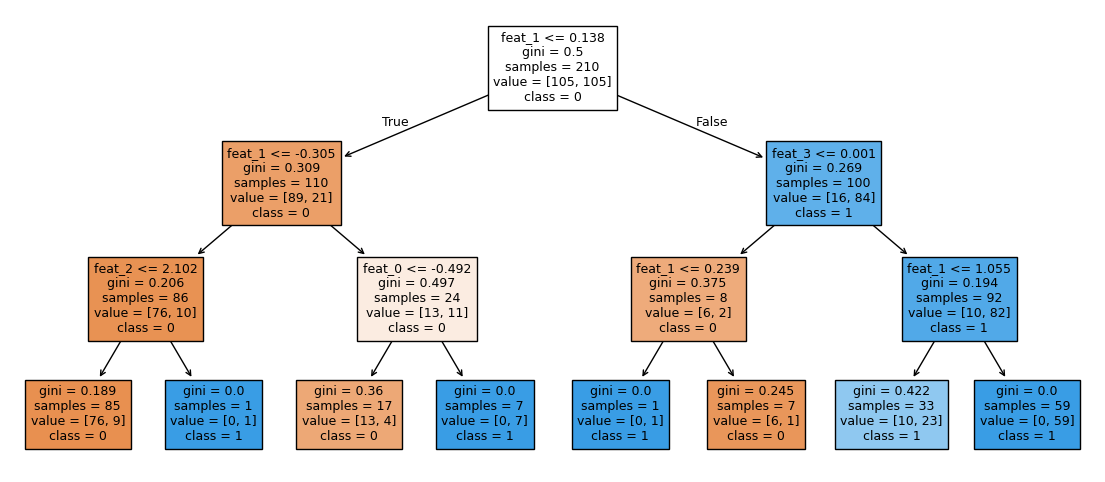

|--- feat_1 <= 0.14
|   |--- feat_1 <= -0.31
|   |   |--- feat_2 <= 2.10
|   |   |   |--- class: 0
|   |   |--- feat_2 >  2.10
|   |   |   |--- class: 1
|   |--- feat_1 >  -0.31
|   |   |--- feat_0 <= -0.49
|   |   |   |--- class: 0
|   |   |--- feat_0 >  -0.49
|   |   |   |--- class: 1
|--- feat_1 >  0.14
|   |--- feat_3 <= 0.00
|   |   |--- feat_1 <= 0.24
|   |   |   |--- class: 1
|   |   |--- feat_1 >  0.24
|   |   |   |--- class: 0
|   |--- feat_3 >  0.00
|   |   |--- feat_1 <= 1.06
|   |   |   |--- class: 1
|   |   |--- feat_1 >  1.06
|   |   |   |--- class: 1



In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

X_dt, y_dt = make_classification(n_samples=300, n_features=4, n_informative=3, n_redundant=0, random_state=42)
feature_names_dt = [f"feat_{i}" for i in range(4)]
X_dt_train, X_dt_test, y_dt_train, y_dt_test = train_test_split(X_dt, y_dt, test_size=0.3, random_state=42)

tree_model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_dt_train, y_dt_train)

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree_model, feature_names=feature_names_dt, class_names=["0", "1"], filled=True, ax=ax, fontsize=9)
plt.show()

print(export_text(tree_model, feature_names=feature_names_dt))


### Model Inspection — Fitted Attributes


In [8]:
print("feature_importances_:", tree_model.feature_importances_.round(3))
print("n_features_in_:", tree_model.n_features_in_)
print("classes_:", tree_model.classes_)
print("tree_.max_depth (actual, may be < requested max_depth):", tree_model.get_depth())
print("tree_.n_leaves:", tree_model.get_n_leaves())
print()
print("predict_proba() for a single tree -- computed from the LEAF's class distribution:")
print(tree_model.predict_proba(X_dt_test[:3]).round(3))


feature_importances_: [0.086 0.8   0.024 0.09 ]
n_features_in_: 4
classes_: [0 1]
tree_.max_depth (actual, may be < requested max_depth): 3
tree_.n_leaves: 8

predict_proba() for a single tree -- computed from the LEAF's class distribution:
[[0.    1.   ]
 [0.303 0.697]
 [0.894 0.106]]


### Line-by-Line Explanation
- `plot_tree()` — a built-in Matplotlib-based visualization requiring no external tools (unlike older `graphviz`-based approaches); `filled=True` colors nodes by predicted class, with color intensity reflecting prediction confidence at that node.
- `export_text()` — a plain-text alternative, useful when a visual plot isn't convenient (e.g., logging, non-notebook environments) or the tree is too large to render legibly.
- `tree_model.predict_proba()` for a single Decision Tree is simply **the class distribution of training samples that landed in the same leaf** — this is why a single tree's probabilities are often poorly calibrated/overconfident (frequently near 0 or 1, since deep leaves can be nearly pure) — a direct motivation for why ensembles (Chapter 20) average over many trees to produce smoother, generally better-calibrated probability estimates.
- `tree_model.get_depth()` can be **less** than the requested `max_depth` if the tree naturally stops splitting earlier (e.g., all remaining samples in a branch are already pure) — worth checking, not just assuming the requested depth was fully used.

### Pruning: `ccp_alpha`


In [9]:
from sklearn.metrics import accuracy_score

path = tree_model.cost_complexity_pruning_path(X_dt_train, y_dt_train)
ccp_alphas = path.ccp_alphas

print(f"{'ccp_alpha':>12}{'Train Acc':>12}{'Test Acc':>12}{'N Leaves':>10}")
for alpha in ccp_alphas[::max(1, len(ccp_alphas)//6)]:   # sample a handful across the range
    pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha).fit(X_dt_train, y_dt_train)
    train_acc = pruned.score(X_dt_train, y_dt_train)
    test_acc = pruned.score(X_dt_test, y_dt_test)
    print(f"{alpha:>12.4f}{train_acc:>12.4f}{test_acc:>12.4f}{pruned.get_n_leaves():>10}")


   ccp_alpha   Train Acc    Test Acc  N Leaves
      0.0000      1.0000      0.8556        31
      0.0061      0.9714      0.8778        20
      0.0075      0.9619      0.8778        18
      0.0185      0.9048      0.8778         8
      0.0243      0.8429      0.8222         3
      0.0288      0.8238      0.8222         2
      0.2102      0.5000      0.5000         1


### Internal Working
`cost_complexity_pruning_path()` computes the sequence of `ccp_alpha` values at which the tree's optimal pruned structure changes — post-pruning (grow a large tree, then prune back based on a complexity penalty) is an alternative complexity-control strategy to pre-pruning (limiting `max_depth`/`min_samples_leaf` upfront), sometimes finding a better bias-variance tradeoff since it considers the fully-grown tree's structure before deciding what to cut.

### Common Mistakes
- Trusting a single Decision Tree's `predict_proba()` as a well-calibrated probability — leaf-based probabilities are frequently overconfident, especially for deep trees with small, pure leaves.
- Growing a tree with no `max_depth`/`min_samples_leaf` constraint at all and being surprised by severe overfitting — an unconstrained tree will keep splitting until every leaf is pure (or has 1 sample), essentially memorizing the training set.
- Assuming `tree_model.get_depth()` always equals the requested `max_depth` — not necessarily true, as shown above.

### Best Practices
- Always constrain tree growth via `max_depth`, `min_samples_leaf`, or `ccp_alpha` — never fit an unconstrained single tree on real data.
- Use `plot_tree()`/`export_text()` for interpretability — a key genuine advantage of a single (shallow) tree over an ensemble, worth leveraging when interpretability specifically matters.
- Prefer an ensemble (Chapter 20) over a single tree whenever raw predictive performance (not interpretability) is the priority.

### Interview Insight
**Q: Why is a single Decision Tree's `predict_proba()` often poorly calibrated, and how does this motivate ensemble methods?**
A: A single tree's predicted probability for a sample is just the class distribution of training points that landed in the same leaf — for a sufficiently deep tree, leaves are often small and nearly pure (all-or-mostly one class), producing probabilities clustered near 0 or 1 regardless of genuine underlying uncertainty. Averaging predictions across many different trees (each trained on a different bootstrap sample and/or feature subset, as in Random Forest) smooths this out, since different trees disagree in different ways on ambiguous samples, producing a probability estimate that reflects genuine ensemble-wide uncertainty rather than one tree's potentially overconfident leaf statistic.

### Mini Exercise
Grow a fully unconstrained `DecisionTreeClassifier()` (no `max_depth`) on `X_dt_train`, check `.get_depth()` and `.get_n_leaves()`, and compare its train vs. test accuracy to the constrained `max_depth=3` version above — a direct, concrete overfitting demonstration.

### Quiz (Chapter 19)
1. What determines a single Decision Tree's `predict_proba()` output for a given sample?
2. What's the difference between pre-pruning (`max_depth`) and post-pruning (`ccp_alpha`)?
3. Why might `tree_model.get_depth()` be less than the requested `max_depth`?


---
# CHAPTER 20 — ENSEMBLE LEARNING (OVERVIEW MAP)

## 1. Concept
An ensemble combines multiple models' predictions, typically outperforming any single constituent model — Scikit-learn's `sklearn.ensemble` module provides three broad ensemble *strategies*, each solving a different problem:

| Strategy | Idea | Reduces |
|---|---|---|
| **Bagging** (Bootstrap AGGregat-ING) | Train many models independently on different random bootstrap samples of the data, then average/vote | **Variance** — Random Forest, `BaggingClassifier`/`Regressor` |
| **Boosting** | Train models **sequentially**, each new model specifically focused on correcting the previous models' errors | **Bias** (and variance) — Gradient Boosting, `AdaBoost`, `HistGradientBoosting` |
| **Stacking/Voting** | Combine **different types** of already-trained models, either by simple voting/averaging or by training a meta-model on their outputs | Leverages diverse model "opinions" |

## 2. The Full Roster


In [10]:
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X_ens, y_ens = make_classification(n_samples=500, n_features=10, n_informative=6, random_state=42)
X_ens_train, X_ens_test, y_ens_train, y_ens_test = train_test_split(X_ens, y_ens, test_size=0.3, random_state=42)

roster = {
    "Bagging (RandomForest)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Bagging (ExtraTrees)": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging (generic BaggingClassifier)": BaggingClassifier(n_estimators=100, random_state=42),
    "Boosting (GradientBoosting)": GradientBoostingClassifier(random_state=42),
    "Boosting (HistGradientBoosting)": HistGradientBoostingClassifier(random_state=42),
    "Boosting (AdaBoost)": AdaBoostClassifier(random_state=42),
}

print(f"{'Model':<38}{'Test Accuracy':>16}")
for name, model in roster.items():
    model.fit(X_ens_train, y_ens_train)
    acc = accuracy_score(y_ens_test, model.predict(X_ens_test))
    print(f"{name:<38}{acc:>16.4f}")


Model                                    Test Accuracy
Bagging (RandomForest)                          0.8600
Bagging (ExtraTrees)                            0.8800
Bagging (generic BaggingClassifier)             0.8867
Boosting (GradientBoosting)                     0.8733
Boosting (HistGradientBoosting)                 0.9133
Boosting (AdaBoost)                             0.7400


In [11]:
# Voting and Stacking -- COMBINING already-different model types
voting_clf = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("svc", SVC(probability=True)),
    ],
    voting="soft",   # "soft" averages predicted PROBABILITIES; "hard" takes a majority vote of predicted LABELS
)
voting_clf.fit(X_ens_train, y_ens_train)
voting_acc = accuracy_score(y_ens_test, voting_clf.predict(X_ens_test))

stacking_clf = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
    ],
    final_estimator=LogisticRegression(max_iter=1000),   # a META-MODEL trained on the base models' outputs
    cv=5,   # internally cross-validated to avoid the meta-model overfitting to the base models' training predictions
)
stacking_clf.fit(X_ens_train, y_ens_train)
stacking_acc = accuracy_score(y_ens_test, stacking_clf.predict(X_ens_test))

print(f"VotingClassifier (soft):  {voting_acc:.4f}")
print(f"StackingClassifier:       {stacking_acc:.4f}")


VotingClassifier (soft):  0.9000
StackingClassifier:       0.8600


### Line-by-Line Explanation
- `VotingClassifier(voting="soft")` — averages each base model's `predict_proba()` output, then takes the argmax; generally preferred over `voting="hard"` (majority vote of hard labels) when every base model supports `predict_proba()`, since it uses more information (confidence, not just the final decision) from each model.
- `StackingClassifier(..., cv=5)` — internally, base models' out-of-fold predictions (via cross-validation) become the **input features** for `final_estimator`, which learns how to best combine them. The `cv=5` is essential: without cross-validation, the meta-model would train on base models' predictions on data those same base models were *also* trained on — a subtle leakage pattern (the base models would look artificially good on their own training data, biasing the meta-model's learned combination weights).
- `SVC(probability=True)` — required specifically so `SVC` can participate in a `voting="soft"` ensemble, which needs every base estimator to expose `predict_proba()` (recall Chapter 17's note that this flag adds real computational cost).

### When to Reach for Each Strategy
- **Bagging (Random Forest)**: your default, robust, hard-to-beat baseline for tabular data — low tuning burden, resistant to overfitting via averaging.
- **Boosting (Gradient Boosting/HistGradientBoosting)**: often edges out bagging on raw performance, at the cost of more careful tuning (Chapter 22) and higher overfitting risk if under-regularized.
- **Voting**: a quick way to combine a few already-strong, meaningfully different models with minimal extra machinery.
- **Stacking**: more powerful than voting when the base models' *patterns of error* are genuinely different (a linear model and a tree ensemble tend to err in different ways) and you have enough data to reliably train the extra meta-model layer without overfitting it.

### Common Mistakes
- Using `StackingClassifier` without adequate `cv` — trains the meta-model on leaked, overly-optimistic base-model predictions.
- Voting/stacking together several near-identical model types (e.g., 3 different Random Forests with slightly different `n_estimators`) — ensembles benefit most from genuinely **diverse** errors; combining very similar models adds complexity with little benefit.
- Assuming an ensemble always beats every individual base model — usually true, but not guaranteed, especially if one base model is meaningfully worse than the others and drags down a simple unweighted vote.

### Best Practices
- Start with Random Forest as a strong, low-effort bagging baseline.
- Reach for boosting when squeezing out additional performance justifies the extra tuning effort.
- Use voting/stacking specifically to combine models with genuinely different strengths/error patterns (e.g., a linear model + a tree ensemble + KNN), not near-duplicates of the same algorithm.

### Interview Insight
**Q: What's the fundamental difference between bagging and boosting, in terms of what each is trying to fix?**
A: Bagging trains many models **independently and in parallel** on different bootstrap samples of the data, then averages/votes their predictions — this primarily reduces **variance** (overfitting to any one sample of the data), since averaging smooths out each individual model's idiosyncratic errors. Boosting trains models **sequentially**, with each new model specifically focused on the mistakes the previous models made — this primarily reduces **bias**, since the ensemble as a whole can represent a more complex function than any single weak model, at the cost of a higher risk of overfitting if not carefully regularized (via learning rate, tree depth, number of estimators).

### Mini Exercise
Build a `VotingClassifier` with `voting="hard"` instead of `"soft"` using the same three base estimators, and compare its accuracy to the soft-voting version above.

### Quiz (Chapter 20)
1. What does bagging primarily reduce, and how? What about boosting?
2. Why does `StackingClassifier` need internal cross-validation (`cv=`) to avoid leakage?
3. When would you prefer voting/stacking over simply using the single best individual model?
4. Why must `SVC` have `probability=True` to participate in a `voting="soft"` ensemble?

### Chapter 20 Summary
- Three ensemble strategies: bagging (parallel, reduces variance — Random Forest), boosting (sequential, reduces bias — Gradient Boosting), and voting/stacking (combine diverse already-different models).
- `StackingClassifier`'s internal `cv=` is essential to prevent the meta-model from learning on leaked, overly-optimistic base-model predictions.

---

## END OF NOTEBOOK 4 — What You Should Now Be Able To Do
- Explain KNN's inverted cost profile (cheap to train, expensive to predict) and correctly tune `n_neighbors` for the bias-variance tradeoff.
- Use SVM's kernel trick conceptually, know when to use `LinearSVC` over `SVC(kernel='linear')`, and recognize SVM's scaling limitations.
- Choose the correct Naive Bayes variant for a given feature type and explain why it remains a strong, fast baseline especially for text.
- Navigate the professional Decision Tree API (`plot_tree`, `export_text`, `cost_complexity_pruning_path`, fitted attributes) and explain why a single tree's probabilities are often poorly calibrated.
- Distinguish bagging, boosting, and voting/stacking conceptually and know when to reach for each — plus the critical leakage-prevention role of `StackingClassifier`'s internal cross-validation.

## Before Moving to Notebook 5 (Chapters 21–25: Random Forest Integration, Gradient Boosting, Model Selection overview, Cross-Validation Deeply, Hyperparameter Tuning)

